# Predicting Canadian Urban Transit Ridership in a Changing Fuel-Price Environment

**CSCN8010 Extra-Credit Project**

**Question:** How can historical transit demand and gasoline-price information be combined to anticipate monthly Canadian urban transit ridership?

**Forecast:** Total Canadian urban transit passenger trips in month *t* (millions), using observed demand and gasoline prices no later than *t-3*.

**Scope:** Canada, monthly, January 2017 through December 2025. Observations from 2026 are excluded.

## 0. Setup

All paths are relative to the repository root, so the notebook runs without manual edits.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
OUTPUT_DIR = Path("outputs")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRANSIT_CSV = RAW_DIR / "23100251.csv"
GASOLINE_CSV = RAW_DIR / "18100001.csv"

SCOPE_START = "2017-01"
SCOPE_END = "2025-12"
DEV_END = "2024-12"

GEO = "Canada"
NAICS_COLUMN = "North American Industry Classification System (NAICS)"
NAICS = "Urban transit systems [485110]"
MEASURE_COLUMN = "Total revenue and total passenger trips"
MEASURE = "Total passenger trips"
FUEL_COLUMN = "Type of fuel"
FUEL = "Regular unleaded gasoline at self service filling stations"

FEATURES = [
    "trips_lag3",
    "trips_lag12",
    "gasoline_lag3",
    "month_sin",
    "month_cos",
    "time_index",
]
TARGET = "trips_millions"

# Figures are interactive in Jupyter and VS Code. A static PNG copy is embedded as well, so the figures
# still appear where interactive output is not supported, such as GitHub's notebook preview.
# The PNG copy needs kaleido and a Chrome browser; without them, figures are interactive only.
try:
    go.Figure().to_image(format="png")
    pio.renderers["png"].width = 1000
    pio.renderers.default = "plotly_mimetype+png"
except Exception as error:
    pio.renderers.default = "plotly_mimetype"
    print(f"Static PNG copies disabled ({type(error).__name__}); figures will be interactive only.")


## 1. Data engineering life cycle

| Stage | Implementation in this project |
|---|---|
| Source and acquisition | Two official Statistics Canada tables are used: 23-10-0251-01 (passenger trips, the outcome) and 18-10-0001-01 (gasoline prices, a potential contributing factor). Both were downloaded as full-table CSVs on November 11, 2026. The README records their provenance and checksums. Section 2 loads the preserved CSVs using relative paths. |
| Storage | The unmodified source files stay in `data/raw/`. Generated files are written only to `data/processed/` and `outputs/`, and the notebook never writes to `data/raw/`. |
| Ingestion and validation | Section 3 checks the schema, data types, dimension members, and status flags. It applies the exact filters and checks units, missing values, duplicate months, and calendar continuity. A wrong unit or a duplicated month stops the notebook. |
| Transformation and integration | Section 4 parses `REF_DATE` as a month and `VALUE` as a number. It reduces each series to one row per month on a complete calendar, then joins them on month with one-to-one validation and reports any unmatched months. |
| Serving and use | `monthly_transportation.csv` is read back for the EDA in Section 5 and the features in Section 6. `model_data.csv` feeds the model in Sections 7-8, and `predictions_2025.csv` stores the test results. |
| Reproducibility and maintenance | `requirements.txt` pins exact package versions, and the README gives run instructions. Restart and Run All recreates every output from `data/raw/`. Section 10 explains how a later data release would be processed. |


## 2. Source and acquisition

The two preserved Statistics Canada CSVs play different roles:

- **Table 23-10-0251-01** is the outcome: passenger trips.
- **Table 18-10-0001-01** is a potential contributing factor: the price of gasoline.

Neither table establishes why anyone chose to travel, and combining them does not establish causation.

In [2]:
transit_raw = pd.read_csv(TRANSIT_CSV)
gasoline_raw = pd.read_csv(GASOLINE_CSV)

for name, frame in [("Transit", transit_raw), ("Gasoline", gasoline_raw)]:
    print(f"{name}: {frame.shape[0]:,} rows, {frame.shape[1]} columns, "
          f"REF_DATE {frame['REF_DATE'].min()} to {frame['REF_DATE'].max()}")


Transit: 1,160 rows, 16 columns, REF_DATE 2017-01 to 2026-08
Gasoline: 46,262 rows, 15 columns, REF_DATE 1979-01 to 2026-09


## 3. Ingestion and validation

Inspect columns, data types, descriptive statistics, missing values, and status flags. Apply the exact geography, industry, measure, fuel, and date filters. Check units, duplicates, and calendar continuity.

In [3]:
# Schema, data types, descriptive statistics, missing values, and status flags
DIMENSION_COLUMNS = {
    "Transit": ["GEO", NAICS_COLUMN, MEASURE_COLUMN, "UOM", "SCALAR_FACTOR"],
    "Gasoline": ["GEO", FUEL_COLUMN, "UOM", "SCALAR_FACTOR"],
}

for name, frame in [("Transit", transit_raw), ("Gasoline", gasoline_raw)]:
    print(f"========== {name}: {frame.shape[0]:,} rows ==========")
    frame.info()
    print("\nMissing values per column:")
    print(frame.isna().sum().to_string())
    print("\nStatus flags across the whole table:")
    for flag in ["STATUS", "SYMBOL", "TERMINATED"]:
        print(f"  {flag}: {frame[flag].value_counts(dropna=False).to_dict()}")
    print("\nDimension members:")
    for column in DIMENSION_COLUMNS[name]:
        print(f"  {column}: {sorted(frame[column].unique())}")
    print()


========== Transit: 1,160 rows ==========
<class 'pandas.DataFrame'>
RangeIndex: 1160 entries, 0 to 1159
Data columns (total 16 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   REF_DATE                                               1160 non-null   str    
 1   GEO                                                    1160 non-null   str    
 2   DGUID                                                  464 non-null    str    
 3   North American Industry Classification System (NAICS)  1160 non-null   str    
 4   Total revenue and total passenger trips                1160 non-null   str    
 5   UOM                                                    1160 non-null   str    
 6   UOM_ID                                                 1160 non-null   int64  
 7   SCALAR_FACTOR                                          1160 non-null   str    
 8   SCALAR_ID        

In [4]:
# Exact filters for each selection
def select_series(frame, filters, label):
    """Keep rows that exactly match every dimension filter and fall in 2017-2025."""
    selected = frame
    for column, value in filters.items():
        if value not in set(frame[column]):
            raise ValueError(f"{label}: '{value}' not found in column '{column}'")
        selected = selected[selected[column] == value]

    selected = selected.copy()
    # A strict format makes any malformed REF_DATE raise an error instead of passing silently
    selected["month"] = pd.to_datetime(selected["REF_DATE"], format="%Y-%m")

    start, end = pd.Timestamp(SCOPE_START), pd.Timestamp(SCOPE_END)
    before = (selected["month"] < start).sum()
    after = (selected["month"] > end).sum()
    in_scope = selected[selected["month"].between(start, end)]
    print(f"{label}: {len(selected)} rows match the filters; "
          f"{len(in_scope)} kept for {SCOPE_START} to {SCOPE_END}; "
          f"excluded {before} earlier and {after} later rows")
    return in_scope


transit_sel = select_series(
    transit_raw,
    {"GEO": GEO, NAICS_COLUMN: NAICS, MEASURE_COLUMN: MEASURE},
    "Transit",
)
gasoline_sel = select_series(
    gasoline_raw,
    {"GEO": GEO, FUEL_COLUMN: FUEL},
    "Gasoline",
)


Transit: 116 rows match the filters; 108 kept for 2017-01 to 2025-12; excluded 0 earlier and 8 later rows
Gasoline: 249 rows match the filters; 108 kept for 2017-01 to 2025-12; excluded 132 earlier and 9 later rows


In [5]:
# Validation: units, duplicates per month, and calendar continuity
EXPECTED_MONTHS = pd.date_range(SCOPE_START, SCOPE_END, freq="MS")


def validate_series(selected, label):
    numeric = pd.to_numeric(selected["VALUE"], errors="coerce")
    return pd.Series(
        {
            "rows": len(selected),
            "unique months": selected["month"].nunique(),
            "expected months": len(EXPECTED_MONTHS),
            "duplicate month rows": int(selected["month"].duplicated(keep=False).sum()),
            "missing calendar months": len(EXPECTED_MONTHS.difference(selected["month"])),
            "missing VALUE": int(selected["VALUE"].isna().sum()),
            "non-numeric VALUE": int((numeric.isna() & selected["VALUE"].notna()).sum()),
            "STATUS flags": int(selected["STATUS"].notna().sum()),
            "SYMBOL flags": int(selected["SYMBOL"].notna().sum()),
            "TERMINATED flags": int(selected["TERMINATED"].notna().sum()),
            "unit (UOM)": ", ".join(selected["UOM"].unique()),
            "scale (SCALAR_FACTOR)": ", ".join(selected["SCALAR_FACTOR"].unique()),
        },
        name=label,
    )


validation = pd.concat(
    [validate_series(transit_sel, "Transit"), validate_series(gasoline_sel, "Gasoline")],
    axis=1,
)
display(validation)

# Hard stops: a wrong unit or a duplicated month would make the join meaningless
assert validation.loc["unit (UOM)", "Transit"] == "Number"
assert validation.loc["scale (SCALAR_FACTOR)", "Transit"] == "millions"
assert validation.loc["unit (UOM)", "Gasoline"] == "Cents per litre"
assert validation.loc["scale (SCALAR_FACTOR)", "Gasoline"] == "units"
assert (validation.loc["duplicate month rows"] == 0).all(), "Duplicate months found: inspect them, do not drop silently"

# Soft checks: report problems instead of hiding them; absent months are reindexed in Section 4
for check in ["missing calendar months", "missing VALUE", "non-numeric VALUE",
              "STATUS flags", "SYMBOL flags", "TERMINATED flags"]:
    for label in validation.columns:
        if validation.loc[check, label] != 0:
            print(f"WARNING: {label} has {validation.loc[check, label]} {check}")

print("\nDescriptive statistics for the selected series:")
display(pd.DataFrame({
    "Transit (millions of trips)": transit_sel["VALUE"].describe(),
    "Gasoline (cents per litre)": gasoline_sel["VALUE"].describe(),
}))


,Transit,Gasoline
rows,108,108
unique months,108,108
expected months,108,108
duplicate month rows,0,0
missing calendar months,0,0
missing VALUE,0,0
non-numeric VALUE,0,0
STATUS flags,0,0
SYMBOL flags,0,0
TERMINATED flags,0,0



Descriptive statistics for the selected series:


,Transit (millions of trips),Gasoline (cents per litre)
count,108.000000,108.000000
mean,119.497222,135.238889
std,37.273838,24.387525
min,25.700000,77.800000
25%,95.350000,115.750000
50%,130.050000,134.900000
75%,148.275000,151.750000
max,169.200000,207.200000


## 4. Transformation and integration

Parse `REF_DATE` as a monthly date and `VALUE` as numeric. Reduce each selection to one row per month. Join by month with one-to-one validation, and report unmatched months before accepting the result. Save `data/processed/monthly_transportation.csv`.

Suppressed or unavailable values are never converted to zeros, the target is never imputed, and extreme periods such as the pandemic are retained.

In [6]:
# Clean each series and rename to trips_millions and gasoline_cents_per_litre
def to_monthly_series(selected, value_name):
    """One row per month on a complete monthly calendar, with VALUE as numbers."""
    values = pd.to_numeric(selected["VALUE"], errors="coerce")
    series = values.set_axis(selected["month"]).sort_index().rename(value_name)
    # Months absent from the source become NaN, never zero, and are reported
    return series.reindex(EXPECTED_MONTHS).rename_axis("month").reset_index()


transit = to_monthly_series(transit_sel, "trips_millions")
gasoline = to_monthly_series(gasoline_sel, "gasoline_cents_per_litre")

for name, frame in [("transit", transit), ("gasoline", gasoline)]:
    print(f"{name}: {len(frame)} months, {frame.iloc[:, 1].isna().sum()} missing values, "
          f"{frame['month'].min():%Y-%m} to {frame['month'].max():%Y-%m}")


transit: 108 months, 0 missing values, 2017-01 to 2025-12
gasoline: 108 months, 0 missing values, 2017-01 to 2025-12


In [7]:
# Report unmatched months, join one-to-one, and save monthly_transportation.csv
joined = transit.merge(
    gasoline,
    on="month",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

print("Join result by source:")
print(joined["_merge"].value_counts().to_string())
unmatched = joined[joined["_merge"] != "both"]
print(f"\nUnmatched months: {len(unmatched)}")
if not unmatched.empty:
    display(unmatched)
    raise ValueError("Unmatched months found: investigate before accepting the join")

monthly = joined.drop(columns="_merge").sort_values("month").reset_index(drop=True)

assert monthly["month"].is_unique
assert len(monthly) == len(EXPECTED_MONTHS)
print(f"Joined dataset: {len(monthly)} rows, "
      f"{monthly['month'].min():%Y-%m} to {monthly['month'].max():%Y-%m}")
print("Missing values after join:", monthly.isna().sum().to_dict())

monthly_path = PROCESSED_DIR / "monthly_transportation.csv"
monthly.to_csv(monthly_path, index=False, date_format="%Y-%m")
print(f"Saved {monthly_path}")
display(monthly.head())


Join result by source:
_merge
both          108
left_only       0
right_only      0

Unmatched months: 0
Joined dataset: 108 rows, 2017-01 to 2025-12
Missing values after join: {'month': 0, 'trips_millions': 0, 'gasoline_cents_per_litre': 0}
Saved data/processed/monthly_transportation.csv


,month,trips_millions,gasoline_cents_per_litre
0,2017-01-01,144.2,112.2
1,2017-02-01,143.6,106.5
2,2017-03-01,166.2,106.0
3,2017-04-01,144.4,116.1
4,2017-05-01,144.5,110.9


### Validation summary

No cleaning correction was needed. The following checks established this:

- **Selection:** Each exact filter matched one series. Transit had 116 matching rows, of which 8 from 2026 were excluded. Gasoline had 249, of which 132 before 2017 and 9 from 2026 were excluded.
- **Completeness:** Both series have 108 unique months from January 2017 to December 2025, with no gaps in the calendar and no duplicate months.
- **Values:** No `VALUE` is missing or non-numeric, and no `STATUS`, `SYMBOL`, or `TERMINATED` flag appears in either selection.
- **Units:** Transit trips are published as a number in millions, so 120.2 means 120.2 million trips. Gasoline is in cents per litre. Both scales are kept as published.
- **Join:** The one-to-one join on month matched all 108 months, with none unmatched.

No values were imputed, set to zero, or removed. Extreme months, such as those during the pandemic, are real observations and are kept.

## 5. Exploratory data analysis (2017-2024 development data only)

2025 outcomes stay out of this section.

In [8]:
# Restrict to the development period
# Serving and use: the EDA reads the saved joined dataset rather than intermediate variables
monthly = pd.read_csv(PROCESSED_DIR / "monthly_transportation.csv")
monthly["month"] = pd.to_datetime(monthly["month"], format="%Y-%m")

dev = monthly[monthly["month"] <= pd.Timestamp(DEV_END)].copy()
dev["year"] = dev["month"].dt.year
dev["calendar_month"] = dev["month"].dt.month
assert dev["month"].max() == pd.Timestamp(DEV_END)
print(f"Development data: {len(dev)} months, {dev['month'].min():%Y-%m} to {dev['month'].max():%Y-%m}. "
      f"2025 is held out.")

# Shared chart settings, reused by the graphical report
SOURCE_TRANSIT = "Source: Statistics Canada, Table 23-10-0251-01, urban transit systems [485110], Canada."
SOURCE_GASOLINE = ("Source: Statistics Canada, Table 18-10-0001-01, regular unleaded gasoline "
                   "at self service filling stations, Canada.")
SOURCE_BOTH = ("Sources: Statistics Canada, Tables 23-10-0251-01 (passenger trips) "
               "and 18-10-0001-01 (gasoline prices), Canada.")
COLOR_TRIPS = "#2a78d6"
COLOR_GASOLINE = "#6250d6"
COLOR_BASELINE = "#eb6834"
COLOR_CONTEXT = "#c3c2b7"
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
FONT = "Helvetica Neue, Helvetica, Arial, sans-serif"

# Date-defined periods used to check whether the association is stable over time.
# They describe when months fall, not anything the two tables measure about the pandemic.
PERIODS = [
    ("Jan 2017 to Feb 2020", "2017-01", "2020-02", "#2a78d6"),
    ("Mar 2020 to Dec 2021", "2020-03", "2021-12", "#eb6834"),
    ("Jan 2022 to Dec 2024", "2022-01", "2024-12", "#1baf7a"),
]
PANDEMIC_DECLARED = pd.Timestamp("2020-03-01")


def label_period(months):
    labels = pd.Series(pd.NA, index=months.index, dtype="object")
    for name, start, end, _ in PERIODS:
        labels[months.between(pd.Timestamp(start), pd.Timestamp(end))] = name
    return labels


# One Plotly template so every figure shares fonts, gridlines, and hover styling
axis_style = dict(showline=True, linecolor=INK_MUTED, gridcolor=GRID, zeroline=False,
                  ticks="outside", tickcolor=INK_MUTED, title_font=dict(size=13, color=INK_SECONDARY))
pio.templates["report"] = go.layout.Template(layout=dict(
    font=dict(family=FONT, size=12, color=INK_SECONDARY),
    title=dict(font=dict(size=16, color=INK_PRIMARY), x=0, xanchor="left", xref="paper"),
    paper_bgcolor="white",
    plot_bgcolor="white",
    xaxis=axis_style,
    yaxis=axis_style,
    hovermode="x unified",
    hoverlabel=dict(bgcolor="white", bordercolor=INK_MUTED,
                    font=dict(family=FONT, size=12, color=INK_PRIMARY)),
    legend=dict(bgcolor="rgba(255,255,255,0.85)", font=dict(size=12)),
    margin=dict(l=70, r=30, t=80, b=110),
))
pio.templates.default = "plotly_white+report"


def subplot(row):
    """Keyword arguments that target one row of a subplot figure, or the whole figure."""
    return {} if row is None else {"row": row, "col": 1}


def add_source(fig, text):
    fig.add_annotation(text=text, xref="paper", yref="paper", x=0, y=0, yshift=-75,
                       xanchor="left", yanchor="top", showarrow=False, align="left",
                       font=dict(size=11, color=INK_SECONDARY))


Development data: 96 months, 2017-01 to 2024-12. 2025 is held out.


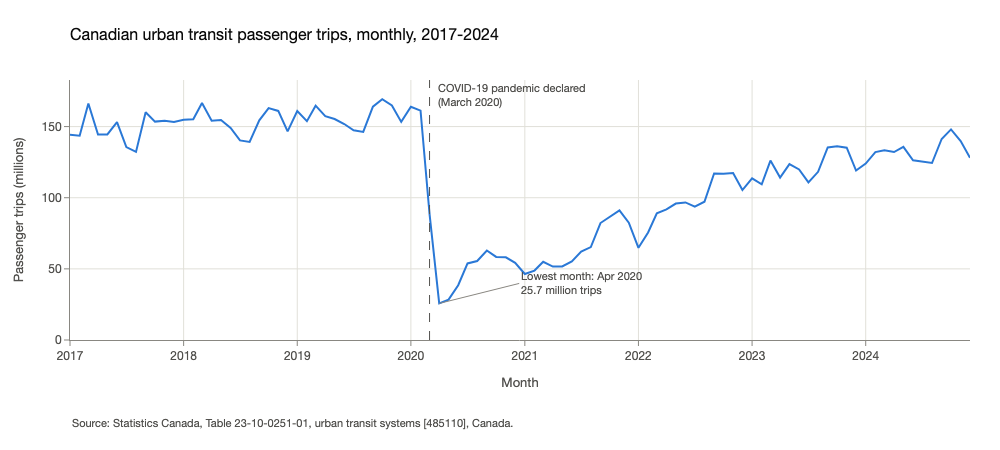

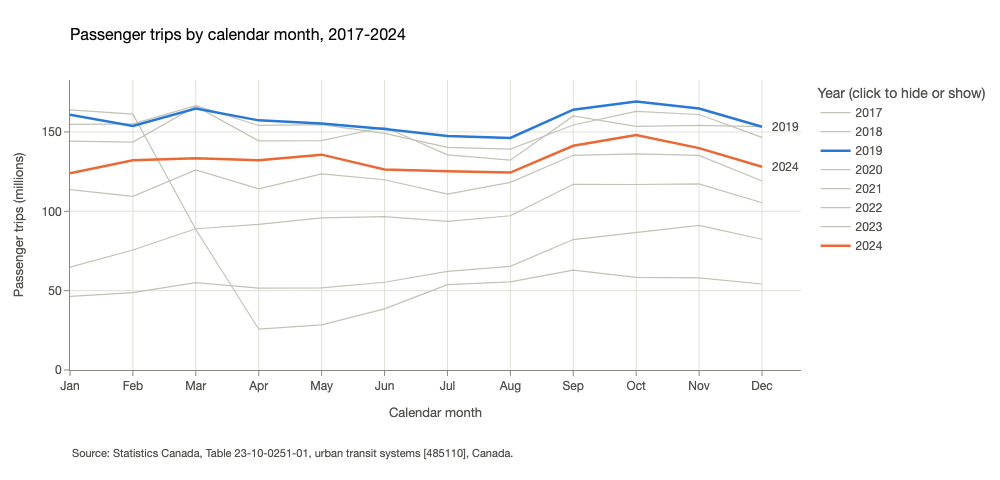

In [9]:
# Ridership over time and across calendar months
def add_ridership(fig, data, row=None):
    """Monthly passenger trips with the March 2020 date and the lowest month annotated."""
    where = subplot(row)
    fig.add_trace(go.Scatter(
        x=data["month"], y=data["trips_millions"], mode="lines", name="Passenger trips",
        line=dict(color=COLOR_TRIPS, width=2),
        hovertemplate="%{y:.1f} million trips<extra></extra>"), **where)
    fig.add_vline(x=PANDEMIC_DECLARED, line=dict(color=INK_SECONDARY, dash="dash", width=1), **where)
    fig.add_annotation(x=PANDEMIC_DECLARED, y=1, yref="y domain", xshift=6, xanchor="left", yanchor="top",
                       text="COVID-19 pandemic declared<br>(March 2020)", showarrow=False, align="left",
                       font=dict(size=11, color=INK_SECONDARY), **where)
    low = data.loc[data["trips_millions"].idxmin()]
    fig.add_annotation(x=low["month"], y=low["trips_millions"], ax=80, ay=-20,
                       text=f"Lowest month: {low['month']:%b %Y}<br>{low['trips_millions']:.1f} million trips",
                       showarrow=True, arrowhead=0, arrowcolor=INK_MUTED, xanchor="left", align="left",
                       font=dict(size=11, color=INK_SECONDARY), **where)
    fig.update_xaxes(hoverformat="%B %Y", **where)
    fig.update_yaxes(title_text="Passenger trips (millions)",
                     range=[0, data["trips_millions"].max() * 1.08], **where)


fig = go.Figure()
add_ridership(fig, dev)
fig.update_layout(title="Canadian urban transit passenger trips, monthly, 2017-2024",
                  xaxis_title="Month", showlegend=False, height=450)
add_source(fig, SOURCE_TRANSIT)
fig.show()

# Same data by calendar month: one line per year, highlighting the last full pre-pandemic year and the latest year.
# Click a year in the legend to hide or show it.
by_month = dev.pivot(index="calendar_month", columns="year", values="trips_millions")
highlight = {2019: COLOR_TRIPS, 2024: COLOR_BASELINE}
month_names = pd.date_range("2024-01", periods=12, freq="MS").strftime("%b")

fig = go.Figure()
for year in sorted(by_month.columns, key=lambda y: y in highlight):
    emphasised = year in highlight
    fig.add_trace(go.Scatter(
        x=list(month_names), y=by_month[year], mode="lines", name=str(year), legendrank=year,
        line=dict(color=highlight.get(year, COLOR_CONTEXT), width=2.5 if emphasised else 1.2),
        hovertemplate=f"{year}: %{{y:.1f}} million<extra></extra>"))
for year in highlight:
    fig.add_annotation(x="Dec", y=by_month.loc[12, year], text=str(year), showarrow=False,
                       xanchor="left", xshift=8, font=dict(size=12, color=INK_SECONDARY))
fig.update_layout(title="Passenger trips by calendar month, 2017-2024",
                  xaxis_title="Calendar month", yaxis_title="Passenger trips (millions)",
                  yaxis_range=[0, by_month.max().max() * 1.08], height=480,
                  legend=dict(title="Year (click to hide or show)"))
add_source(fig, SOURCE_TRANSIT)
fig.show()


In [10]:
# Seasonal pattern and year-over-year change, with dates and numbers
# Seasonal index: each month as a percentage of that year's average month.
# This compares the shape of each year regardless of its overall level.
seasonal_index = by_month / by_month.mean() * 100
seasonal_index.index = month_names
print("Seasonal index (100 = that year's average month):")
display(seasonal_index.round(1))

# 2020-2022 are excluded from the typical pattern because the series collapsed and then rebuilt during those years
typical_years = [2017, 2018, 2019, 2023, 2024]
typical = seasonal_index[typical_years]
summer_below = (typical.loc[["Jul", "Aug"]] < 100).all().all()
print(f"\nIn {typical_years}, July and August were below the yearly average month every time: {summer_below}")
print(f"Average index for those years: July {typical.loc['Jul'].mean():.1f}, August {typical.loc['Aug'].mean():.1f}, "
      f"September {typical.loc['Sep'].mean():.1f}, October {typical.loc['Oct'].mean():.1f}")

aug_2019, oct_2019 = by_month.loc[8, 2019], by_month.loc[10, 2019]
print(f"Example: August 2019 had {aug_2019:.1f} million trips and October 2019 had {oct_2019:.1f} million, "
      f"{(oct_2019 / aug_2019 - 1) * 100:+.1f}%.")

# Year-over-year change
annual = dev.groupby("year")["trips_millions"].agg(total_millions="sum", months="count")
annual["change_vs_previous_year_%"] = annual["total_millions"].pct_change() * 100
annual["percent_of_2019"] = annual["total_millions"] / annual.loc[2019, "total_millions"] * 100
print("\nAnnual passenger trips:")
display(annual.round(1))

apr_2019, apr_2020 = by_month.loc[4, 2019], by_month.loc[4, 2020]
print(f"Same-month change: April 2020 had {apr_2020:.1f} million trips versus {apr_2019:.1f} million "
      f"in April 2019 ({(apr_2020 / apr_2019 - 1) * 100:+.1f}%).")
print(f"Recovery: 2024 had {annual.loc[2024, 'total_millions']:.1f} million trips, "
      f"{annual.loc[2024, 'percent_of_2019']:.1f}% of the 2019 total "
      f"({annual.loc[2019, 'total_millions']:.1f} million).")


Seasonal index (100 = that year's average month):


year,2017,2018,2019,2020,2021,2022,2023,2024
Jan,97.0,101.0,102.2,231.6,71.5,67.0,93.3,93.6
Feb,96.5,101.2,97.7,227.8,75.2,78.1,89.8,99.7
Mar,111.7,108.7,104.6,125.1,84.8,92.0,103.5,100.7
Apr,97.1,100.6,99.9,36.3,79.5,94.9,93.8,99.7
May,97.2,100.9,98.7,40.1,79.7,99.1,101.5,102.4
Jun,102.9,97.3,96.4,54.4,85.3,99.9,98.4,95.3
Jul,91.2,91.6,93.7,76.0,95.7,96.8,91.0,94.5
Aug,88.9,90.8,92.9,78.4,100.7,100.4,97.0,93.9
Sep,107.6,100.8,104.2,88.9,126.7,120.9,111.1,106.6
Oct,103.2,106.4,107.5,82.5,133.4,120.8,111.8,111.7



In [2017, 2018, 2019, 2023, 2024], July and August were below the yearly average month every time: True
Average index for those years: July 92.4, August 92.7, September 106.1, October 108.1
Example: August 2019 had 146.2 million trips and October 2019 had 169.2 million, +15.7%.

Annual passenger trips:


,total_millions,months,change_vs_previous_year_%,percent_of_2019
year,,,,
2017,1784.8,12,NaN,94.5
2018,1838.8,12,3.0,97.4
2019,1888.7,12,2.7,100.0
2020,849.1,12,-55.0,45.0
2021,778.4,12,-8.3,41.2
2022,1161.3,12,49.2,61.5
2023,1461.6,12,25.9,77.4
2024,1590.4,12,8.8,84.2


Same-month change: April 2020 had 25.7 million trips versus 157.3 million in April 2019 (-83.7%).
Recovery: 2024 had 1590.4 million trips, 84.2% of the 2019 total (1888.7 million).


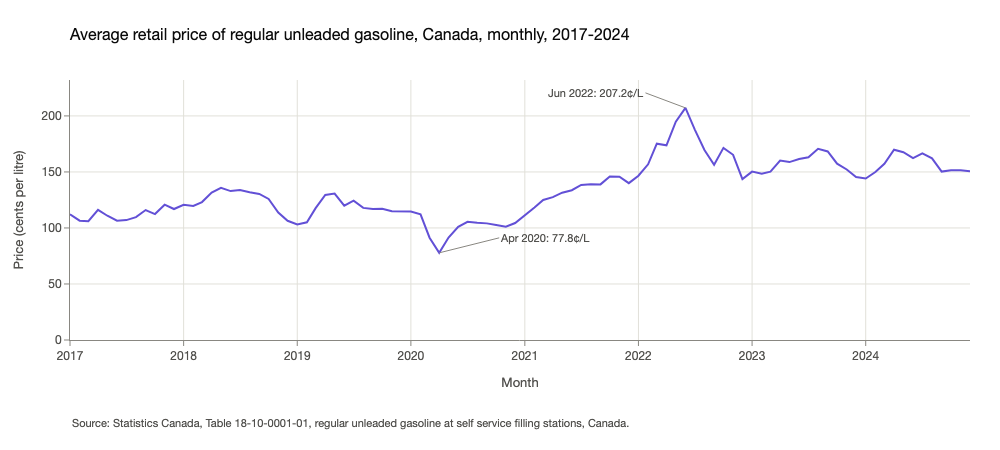

Gasoline price by year (cents per litre):


,mean,min,max
year,,,
2017,111.8,106.0,120.8
2018,125.5,106.4,135.9
2019,117.7,103.1,130.7
2020,100.9,77.8,114.6
2021,132.9,111.0,146.0
2022,170.7,143.6,207.2
2023,157.2,145.4,170.6
2024,157.0,144.1,169.8


In [11]:
# Gasoline prices over the same period
def add_gasoline(fig, data, row=None):
    """Monthly gasoline price with the highest and lowest months annotated."""
    where = subplot(row)
    fig.add_trace(go.Scatter(
        x=data["month"], y=data["gasoline_cents_per_litre"], mode="lines", name="Gasoline price",
        line=dict(color=COLOR_GASOLINE, width=2),
        hovertemplate="%{y:.1f}¢ per litre<extra></extra>"), **where)
    high = data.loc[data["gasoline_cents_per_litre"].idxmax()]
    low = data.loc[data["gasoline_cents_per_litre"].idxmin()]
    for point, ax, anchor in [(high, -40, "right"), (low, 60, "left")]:
        fig.add_annotation(x=point["month"], y=point["gasoline_cents_per_litre"], ax=ax, ay=-15,
                           text=f"{point['month']:%b %Y}: {point['gasoline_cents_per_litre']:.1f}¢/L",
                           showarrow=True, arrowhead=0, arrowcolor=INK_MUTED, xanchor=anchor,
                           font=dict(size=11, color=INK_SECONDARY), **where)
    fig.update_xaxes(hoverformat="%B %Y", **where)
    fig.update_yaxes(title_text="Price (cents per litre)",
                     range=[0, data["gasoline_cents_per_litre"].max() * 1.12], **where)


fig = go.Figure()
add_gasoline(fig, dev)
fig.update_layout(title="Average retail price of regular unleaded gasoline, Canada, monthly, 2017-2024",
                  xaxis_title="Month", showlegend=False, height=450)
add_source(fig, SOURCE_GASOLINE)
fig.show()

gas_annual = dev.groupby("year")["gasoline_cents_per_litre"].agg(["mean", "min", "max"])
print("Gasoline price by year (cents per litre):")
display(gas_annual.round(1))


Correlation between gasoline price at t-3 and passenger trips at t:


Levels           12-month changes          
                       months pearson_r           months pearson_r
All development months     93      0.11               81      0.45
Jan 2017 to Feb 2020       35     -0.09               23     -0.04
Mar 2020 to Dec 2021       22      0.59               22      0.72
Jan 2022 to Dec 2024       36      0.05               36      0.56

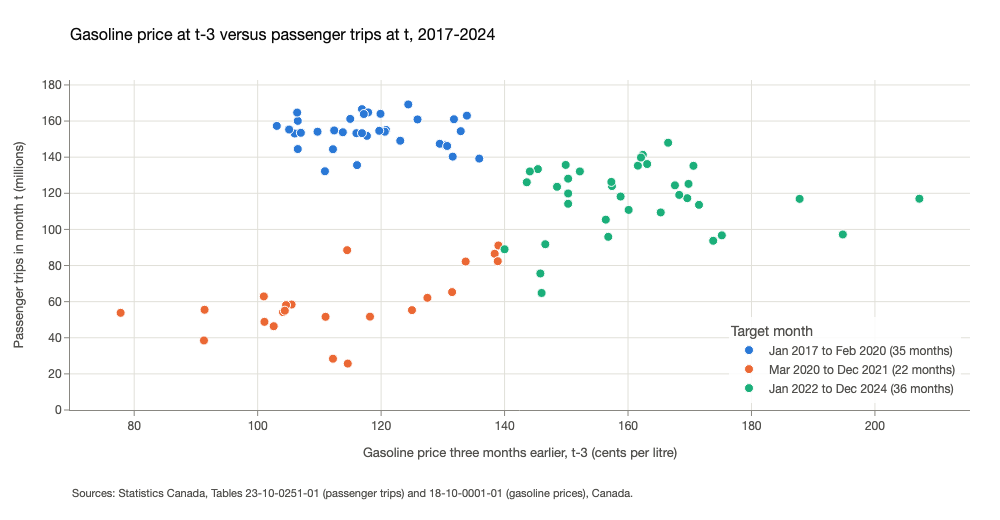

In [12]:
# Earlier gasoline prices versus later ridership, including shared trends and unusual periods
# shift(3) moves each price down three rows, so a target month is paired with the price three months earlier.
# The calendar was verified as continuous, so three rows equal three months.
dev["gasoline_lag3"] = dev["gasoline_cents_per_litre"].shift(3)
dev["period"] = label_period(dev["month"])

# 12-month changes remove the seasonal pattern and slow shared trends, as a check on the level correlation
dev["trips_change_12m"] = dev["trips_millions"].diff(12)
dev["gasoline_lag3_change_12m"] = dev["gasoline_lag3"].diff(12)


def correlation(frame, x, y):
    pair = frame[[x, y]].dropna()
    return pd.Series({"months": len(pair), "pearson_r": pair[x].corr(pair[y])})


rows = {"All development months": correlation(dev, "gasoline_lag3", "trips_millions")}
for name, *_ in PERIODS:
    rows[name] = correlation(dev[dev["period"] == name], "gasoline_lag3", "trips_millions")
levels = pd.DataFrame(rows).T

rows = {"All development months": correlation(dev, "gasoline_lag3_change_12m", "trips_change_12m")}
for name, *_ in PERIODS:
    rows[name] = correlation(dev[dev["period"] == name], "gasoline_lag3_change_12m", "trips_change_12m")
changes = pd.DataFrame(rows).T

association = pd.concat({"Levels": levels, "12-month changes": changes}, axis=1)
association = association.astype({(level, "months"): int for level in ["Levels", "12-month changes"]})
print("Correlation between gasoline price at t-3 and passenger trips at t:")
display(association.round(2))


def add_association(fig, data):
    """Scatter of gasoline at t-3 against trips at t, coloured by date-defined period."""
    for name, _, _, color in PERIODS:
        subset = data[data["period"] == name]
        fig.add_trace(go.Scatter(
            x=subset["gasoline_lag3"], y=subset["trips_millions"], mode="markers",
            name=f"{name} ({len(subset)} months)",
            marker=dict(color=color, size=9, line=dict(color="white", width=1)),
            customdata=subset["month"].dt.strftime("%b %Y"),
            hovertemplate=("<b>%{customdata}</b><br>Gasoline at t-3: %{x:.1f}¢/L"
                           "<br>Trips at t: %{y:.1f} million<extra></extra>")))
    fig.update_layout(hovermode="closest",
                      xaxis_title="Gasoline price three months earlier, t-3 (cents per litre)",
                      yaxis_title="Passenger trips in month t (millions)",
                      legend=dict(title="Target month", x=0.99, xanchor="right", y=0.02, yanchor="bottom"))
    fig.update_yaxes(range=[0, data["trips_millions"].max() * 1.08])


fig = go.Figure()
add_association(fig, dev.dropna(subset=["gasoline_lag3"]))
fig.update_layout(title="Gasoline price at t-3 versus passenger trips at t, 2017-2024", height=520)
add_source(fig, SOURCE_BOTH)
fig.show()


### Talking points

1. **Demand:** Ridership has a repeating seasonal shape and a large disruption. In 2017-2019 and 2023-2024, July and August were below that year's average month every time (average index 92.4 and 92.7), while September and October were the highest on average (106.1 and 108.1). For example, trips rose from 146.2 million in August 2019 to 169.2 million in October 2019 (+15.7%). In April 2020, trips fell to 25.7 million, compared with 157.3 million in April 2019 (-83.7%), and the 2020 annual total fell 55.0%. By 2024, annual ridership of 1,590.4 million was 84.2% of the 2019 total, so it had not returned to the pre-2020 level.

2. **Gasoline prices and their association with demand:** Gasoline ranged from 77.8¢/L in April 2020 to 207.2¢/L in June 2022. Its annual average was 111.8¢/L in 2017, fell to 100.9¢/L in 2020, peaked at 170.7¢/L in 2022, and stayed near 157¢/L in 2023-2024. The association between gasoline at t-3 and trips at t is weak overall (r = 0.11 over 93 months) and changes by period: -0.09 before March 2020, 0.59 from March 2020 to December 2021, and 0.05 in 2022-2024. Using 12-month changes, r is 0.45 overall but -0.04 before 2020. The positive association therefore comes from 2020-2024, when both series fell and recovered at similar times. The scatter plot shows three separate clusters by period, not one consistent relationship.

3. **Limitations and alternative explanations:** These are two national monthly series, and correlation does not establish that gasoline prices change ridership. The shared movement in 2020-2022 coincides with the pandemic period, but neither table measures the pandemic, remote work, fares, service levels, or population. Those remain possible explanations, not findings. Only about three years of data come before March 2020, so any relationship estimated across the whole period mostly reflects the disruption and recovery. I therefore expect the gasoline feature to add little, and the model evaluation will test this rather than assume it.


## 6. Feature engineering

**How the lags are created.** `shift(k)` moves a column down by k rows. The monthly calendar was verified as continuous, with no gaps or duplicates, so moving down k rows gives each month the value from exactly k months earlier. For the January 2018 row:

- `trips_millions.shift(3)` supplies October 2017 trips (153.5 million) as `trips_lag3`.
- `trips_millions.shift(12)` supplies January 2017 trips (144.2 million) as `trips_lag12`.
- `gasoline_cents_per_litre.shift(3)` supplies the October 2017 price (112.4¢/L) as `gasoline_lag3`.

The first 3 rows have no 3-month lag, and the first 12 rows have no 12-month lag. Those values are left blank rather than filled, and the first 12 months (2017) are removed.

**Why there is no leakage.** Each predictor uses only observations from month t-3 or earlier, or the calendar position of month t, which is known in advance. The current-month ridership and gasoline price are not predictors. No centred averages or backward filling are used. Building features before the train/test split is safe because no parameters are estimated from future outcomes. The scaling, which is learned, happens later inside the pipeline.

`time_index` counts months since January 2017 (January 2018 = 12). `month_sin` and `month_cos` place each calendar month on a circle, so December and January sit next to each other.


In [13]:
# Create the six predictors, drop the first 12 months, check the row count and date range, and save
features = (monthly[["month", "trips_millions", "gasoline_cents_per_litre"]]
            .sort_values("month")
            .reset_index(drop=True))

# Row shifts equal month shifts only on a continuous monthly calendar, so check that first
calendar = pd.date_range(features["month"].min(), features["month"].max(), freq="MS")
assert features["month"].is_unique
assert len(features) == len(calendar) and (features["month"].values == calendar.values).all(), \
    "Calendar has gaps: reindex to a monthly calendar before shifting"

# Lagged values: shift(k) gives each row the value from k rows (= k months) earlier
features["trips_lag3"] = features["trips_millions"].shift(3)
features["trips_lag12"] = features["trips_millions"].shift(12)
features["gasoline_lag3"] = features["gasoline_cents_per_litre"].shift(3)

# Calendar features: the target month's own date is known in advance, so it is not leakage
calendar_month = features["month"].dt.month
features["month_sin"] = np.sin(2 * np.pi * calendar_month / 12)
features["month_cos"] = np.cos(2 * np.pi * calendar_month / 12)
start = pd.Timestamp(SCOPE_START)
features["time_index"] = ((features["month"].dt.year - start.year) * 12
                          + (features["month"].dt.month - start.month))

# Remove the first 12 months, where the annual lag does not exist.
# The current-month gasoline price is dropped so it cannot be used as a predictor.
first_model_month = start + pd.DateOffset(months=12)
model_data = (features[features["month"] >= first_model_month]
              [["month", TARGET] + FEATURES]
              .reset_index(drop=True))

# Checks: computed expectations, not hardcoded answers
expected_rows = len(features) - 12
assert len(model_data) == expected_rows
assert model_data[FEATURES].notna().all().all(), "Missing predictor values: an imputer would be needed in the pipeline"
print(f"Modelling table: {len(model_data)} rows (expected {expected_rows}), "
      f"{model_data['month'].min():%Y-%m} to {model_data['month'].max():%Y-%m}")
print(f"Protocol expectation of 96 rows, January 2018 to December 2025: "
      f"{len(model_data) == 96 and model_data['month'].min() == pd.Timestamp('2018-01') and model_data['month'].max() == pd.Timestamp('2025-12')}")

# Leakage check: every lag must equal the source value from exactly k months before its target month
lookup = features.set_index("month")
for column, source, lag in [("trips_lag3", "trips_millions", 3),
                            ("trips_lag12", "trips_millions", 12),
                            ("gasoline_lag3", "gasoline_cents_per_litre", 3)]:
    source_months = model_data["month"] - pd.DateOffset(months=lag)
    assert np.allclose(model_data[column].values, lookup.loc[source_months, source].values), column
print("Lag check passed: trips_lag3, trips_lag12, and gasoline_lag3 come from months t-3, t-12, and t-3.")

model_path = PROCESSED_DIR / "model_data.csv"
model_data.to_csv(model_path, index=False, date_format="%Y-%m")
print(f"Saved {model_path}")
display(model_data.head(3))


Modelling table: 96 rows (expected 96), 2018-01 to 2025-12
Protocol expectation of 96 rows, January 2018 to December 2025: True
Lag check passed: trips_lag3, trips_lag12, and gasoline_lag3 come from months t-3, t-12, and t-3.
Saved data/processed/model_data.csv


,month,trips_millions,trips_lag3,trips_lag12,gasoline_lag3,month_sin,month_cos,time_index
0,2018-01-01,154.8,153.5,144.2,112.4,0.500000,8.660254e-01,12
1,2018-02-01,155.1,154.1,143.6,120.8,0.866025,5.000000e-01,13
2,2018-03-01,166.6,153.3,166.2,116.9,1.000000,6.123234e-17,14


## 7. Chronological split and scikit-learn Pipeline

The training set is January 2018 to December 2024, and the test set is January to December 2025. The observations are not shuffled.

**What `fit` learns.** The pipeline is fitted once, on the 84 training rows only. `StandardScaler` learns the mean and standard deviation of each of the six predictors. `LinearRegression` then learns an intercept and one coefficient per scaled predictor.

**Why `predict` must apply the same preprocessing.** The coefficients were estimated on scaled inputs, so new rows must be scaled the same way before they are multiplied by those coefficients. At prediction time, the pipeline reuses the training means and standard deviations, not values recomputed from 2025. That keeps test data from influencing any learned parameter. Putting both steps in one `Pipeline` guarantees the same transformation is applied, in the same order, at both stages.


In [14]:
# Chronological split, with checks on the expected row counts
# Serving and use: the model reads the saved modelling table
model_data = pd.read_csv(PROCESSED_DIR / "model_data.csv")
model_data["month"] = pd.to_datetime(model_data["month"], format="%Y-%m")

train = model_data[model_data["month"] <= pd.Timestamp(DEV_END)]
test = model_data[model_data["month"] > pd.Timestamp(DEV_END)]

# Expected sizes come from the calendar, not hardcoded numbers
expected_train = len(pd.date_range(model_data["month"].min(), DEV_END, freq="MS"))
expected_test = len(pd.date_range(pd.Timestamp(DEV_END) + pd.DateOffset(months=1), SCOPE_END, freq="MS"))
assert len(train) == expected_train and len(test) == expected_test
assert train["month"].max() < test["month"].min(), "Training months must all come before test months"

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

split_summary = pd.DataFrame({
    "target months": [f"{train['month'].min():%b %Y} to {train['month'].max():%b %Y}",
                      f"{test['month'].min():%b %Y} to {test['month'].max():%b %Y}"],
    "rows": [len(train), len(test)],
    "use": ["Fit the pipeline once", "Evaluate the fixed model and baseline"],
}, index=["Training", "Test"])
display(split_summary)


,target months,rows,use
Training,Jan 2018 to Dec 2024,84,Fit the pipeline once
Test,Jan 2025 to Dec 2025,12,Evaluate the fixed model and baseline


In [15]:
# Build the Pipeline (StandardScaler, then LinearRegression) and fit it once on training data
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression()),
])
pipeline.fit(X_train, y_train)

# What fit learned: scaling parameters from the 84 training rows, then the regression on scaled inputs
scaler = pipeline.named_steps["scaler"]
regression = pipeline.named_steps["regression"]
learned = pd.DataFrame({
    "training mean": scaler.mean_,
    "training std": scaler.scale_,
    "coefficient (millions of trips per 1 std)": regression.coef_,
}, index=FEATURES)
print(f"Intercept: {regression.intercept_:.2f} million trips (the prediction when every predictor is at its training mean)")
display(learned.round(3))
print("A nonzero coefficient does not show that a feature improves predictions; "
      "the test comparison with the baseline is the evidence.")


Intercept: 113.91 million trips (the prediction when every predictor is at its training mean)


,training mean,training std,coefficient (millions of trips per 1 std)
trips_lag3,114.444,40.172,27.767
trips_lag12,116.223,41.296,2.366
gasoline_lag3,136.176,25.671,10.219
month_sin,-0.000,0.707,-4.227
month_cos,-0.000,0.707,4.018
time_index,53.500,24.247,-6.028


A nonzero coefficient does not show that a feature improves predictions; the test comparison with the baseline is the evidence.


## 8. Baseline, evaluation, and predictions

The baseline predicts the same month in the previous year: `prediction_t = trips_(t-12)`. MAE is the primary metric and RMSE is secondary. Both approaches are scored on the same 12 months.

These are successive forecasts from a fixed model on a downloaded, potentially revised snapshot. They are a historical forecasting experiment, not verified live forecasting performance.

In [16]:
# Predictions from the Pipeline and the baseline
# Each test row already holds its own permitted inputs: for example, April 2025 uses January 2025 trips.
# The fitted pipeline is not refit, so these are successive forecasts from one fixed model.
predictions = pd.DataFrame({
    "target_month": test["month"].dt.strftime("%Y-%m").values,
    "actual_trips_millions": y_test.values,
    "baseline_prediction": test["trips_lag12"].values,  # same month in the previous year
    "model_prediction": pipeline.predict(X_test),
})
# Signed error = prediction - actual, so a positive error means the forecast was too high
predictions["baseline_error"] = predictions["baseline_prediction"] - predictions["actual_trips_millions"]
predictions["baseline_abs_error"] = predictions["baseline_error"].abs()
predictions["model_error"] = predictions["model_prediction"] - predictions["actual_trips_millions"]
predictions["model_abs_error"] = predictions["model_error"].abs()
display(predictions.round(2))


,target_month,actual_trips_millions,baseline_prediction,model_prediction,baseline_error,baseline_abs_error,model_error,model_abs_error
0,2025-01,132.0,124.0,135.05,-8.0,8.0,3.05,3.05
1,2025-02,122.0,132.1,125.25,10.1,10.1,3.25,3.25
2,2025-03,137.1,133.4,112.99,-3.7,3.7,-24.11,24.11
3,2025-04,133.9,132.1,115.79,-1.8,1.8,-18.11,18.11
4,2025-05,133.7,135.7,109.34,2.0,2.0,-24.36,24.36
5,2025-06,124.9,126.3,120.07,1.4,1.4,-4.83,4.83
6,2025-07,124.5,125.2,115.08,0.7,0.7,-9.42,9.42
7,2025-08,120.6,124.4,119.91,3.8,3.8,-0.69,0.69
8,2025-09,138.2,141.3,117.80,3.1,3.1,-20.40,20.40
9,2025-10,142.0,148.0,119.26,6.0,6.0,-22.74,22.74


In [17]:
# MAE and RMSE for both approaches
def score(predicted):
    return {
        "MAE (millions of trips)": mean_absolute_error(predictions["actual_trips_millions"], predicted),
        "RMSE (millions of trips)": np.sqrt(mean_squared_error(predictions["actual_trips_millions"], predicted)),
    }


metrics = pd.DataFrame({
    "Seasonal baseline (same month last year)": score(predictions["baseline_prediction"]),
    "Linear regression pipeline": score(predictions["model_prediction"]),
}).T
display(metrics.round(2))

model_mae = metrics.loc["Linear regression pipeline", "MAE (millions of trips)"]
baseline_mae = metrics.loc["Seasonal baseline (same month last year)", "MAE (millions of trips)"]
average_month = predictions["actual_trips_millions"].mean()
print(f"In plain language: across the 12 months of 2025, the model's forecast missed the actual number of "
      f"trips by {model_mae:.1f} million on average, about {model_mae / average_month * 100:.1f}% of an average "
      f"2025 month ({average_month:.1f} million trips). The baseline missed by {baseline_mae:.1f} million on average.")
better = "lower" if model_mae < baseline_mae else "higher"
print(f"The model's MAE is {abs(model_mae - baseline_mae):.1f} million trips {better} than the baseline's "
      f"({(model_mae / baseline_mae - 1) * 100:+.1f}%).")


,MAE (millions of trips),RMSE (millions of trips)
Seasonal baseline (same month last year),5.40,6.75
Linear regression pipeline,12.46,15.11


In plain language: across the 12 months of 2025, the model's forecast missed the actual number of trips by 12.5 million on average, about 9.6% of an average 2025 month (129.4 million trips). The baseline missed by 5.4 million on average.
The model's MAE is 7.1 million trips higher than the baseline's (+130.7%).


In [18]:
# Save outputs/predictions_2025.csv
predictions_path = OUTPUT_DIR / "predictions_2025.csv"
predictions.to_csv(predictions_path, index=False)
print(f"Saved {predictions_path}: {len(predictions)} rows, columns {list(predictions.columns)}")


Saved outputs/predictions_2025.csv: 12 rows, columns ['target_month', 'actual_trips_millions', 'baseline_prediction', 'model_prediction', 'baseline_error', 'baseline_abs_error', 'model_error', 'model_abs_error']


In [19]:
# One worked prediction: target month, input months, prediction, actual value, and error
target = pd.Timestamp("2025-12")
row = test[test["month"] == target]
input_months = {
    "trips_lag3": target - pd.DateOffset(months=3),
    "trips_lag12": target - pd.DateOffset(months=12),
    "gasoline_lag3": target - pd.DateOffset(months=3),
    "month_sin": target,
    "month_cos": target,
    "time_index": target,
}
scaled = pd.Series(scaler.transform(row[FEATURES])[0], index=FEATURES)
worked = pd.DataFrame({
    "input month": [f"{input_months[f]:%b %Y}" for f in FEATURES],
    "value": row[FEATURES].iloc[0].values,
    "scaled value": scaled.values,
    "coefficient": regression.coef_,
    "contribution (millions)": scaled.values * regression.coef_,
}, index=FEATURES)

by_hand = regression.intercept_ + worked["contribution (millions)"].sum()
result = predictions.set_index("target_month").loc[f"{target:%Y-%m}"]
assert np.isclose(by_hand, result["model_prediction"])

print(f"Worked prediction for {target:%B %Y}")
display(worked.round(3))
print(f"Prediction = intercept {regression.intercept_:.2f} + sum of contributions "
      f"{worked['contribution (millions)'].sum():.2f} = {by_hand:.1f} million trips")
print(f"Actual: {result['actual_trips_millions']:.1f} million trips. "
      f"Model error (prediction - actual): {result['model_error']:+.1f} million.")
print(f"Baseline (December 2024 trips): {result['baseline_prediction']:.1f} million, "
      f"error {result['baseline_error']:+.1f} million.")


Worked prediction for December 2025


,input month,value,scaled value,coefficient,contribution (millions)
trips_lag3,Sep 2025,138.2,0.591,27.767,16.420
trips_lag12,Dec 2024,128.1,0.288,2.366,0.680
gasoline_lag3,Sep 2025,144.2,0.313,10.219,3.194
month_sin,Dec 2025,-0.0,-0.000,-4.227,0.000
month_cos,Dec 2025,1.0,1.414,4.018,5.682
time_index,Dec 2025,107.0,2.206,-6.028,-13.301


Prediction = intercept 113.91 + sum of contributions 12.68 = 126.6 million trips
Actual: 117.6 million trips. Model error (prediction - actual): +9.0 million.
Baseline (December 2024 trips): 128.1 million, error +10.5 million.


### Conclusion on the baseline

**The model did not improve on the baseline.** Over January to December 2025, the linear regression pipeline had an MAE of 12.46 million trips and an RMSE of 15.11 million. The same-month-last-year baseline had an MAE of 5.40 million and an RMSE of 6.75 million. In plain language, the model's monthly forecast missed by about 12.5 million trips on average, roughly 9.6% of an average 2025 month (129.4 million trips). The baseline missed by about 5.4 million.

The model under-forecast 9 of the 12 months, most heavily in March-May and September-October, by 18 to 24 million trips. It did not reproduce the autumn rise that the baseline carries over from the previous year. One plausible reason is that the training period includes the 2020 collapse and the recovery that followed. That pulls the fitted linear trend down: `time_index` has a negative coefficient and subtracts 13.3 million trips from the December 2025 forecast.

The gasoline feature has a positive coefficient, but that does not show it adds predictive value. This evaluation does not isolate its contribution, and the model that includes it performed worse than a baseline that uses no gasoline information at all.


## 9. Graphical report

Every figure needs a clear title, labelled axes, units, and source attribution.

### Figures 1 and 2. Problem and context: ridership and gasoline prices over time, in aligned panels

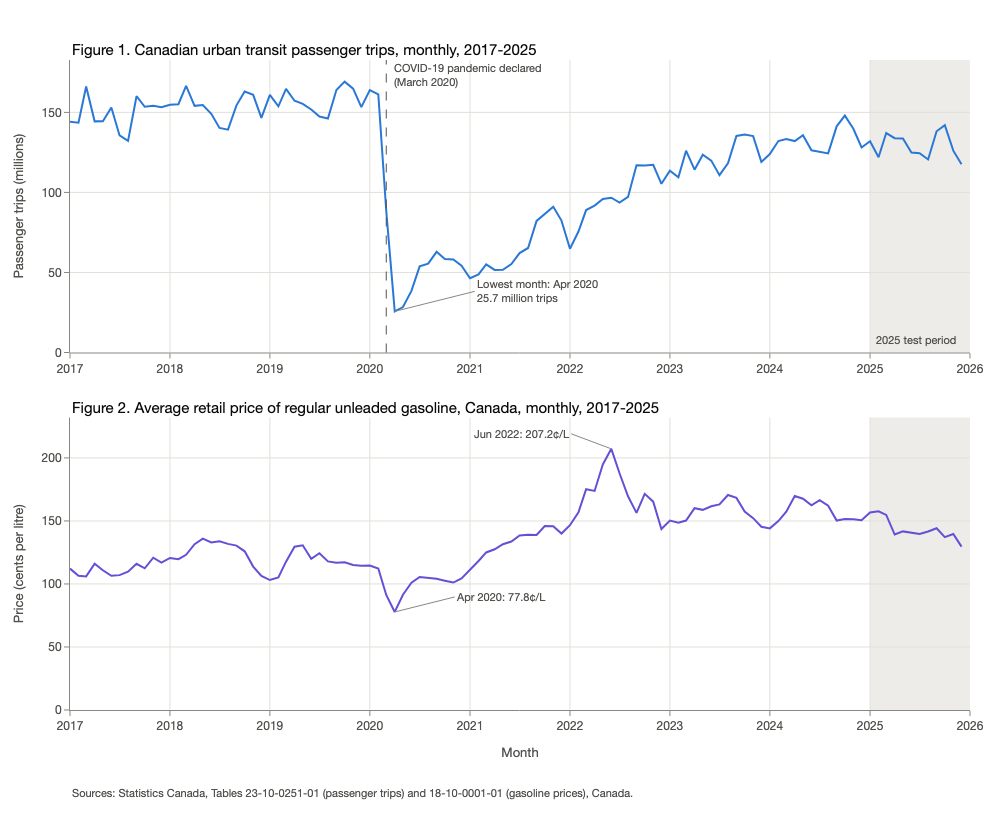

In [20]:
# Figure 1
# Full 2017-2025 series, with the 2025 test period shaded, in two aligned panels sharing one time axis
full = monthly.copy()
test_start = pd.Timestamp(DEV_END) + pd.DateOffset(months=1)
test_end = pd.Timestamp(SCOPE_END) + pd.DateOffset(months=1)

fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.1,
    subplot_titles=("Figure 1. Canadian urban transit passenger trips, monthly, 2017-2025",
                    "Figure 2. Average retail price of regular unleaded gasoline, Canada, monthly, 2017-2025"))
for title in fig.layout.annotations:
    title.update(x=0, xanchor="left", font=dict(size=15, color=INK_PRIMARY))

add_ridership(fig, full, row=1)
add_gasoline(fig, full, row=2)
fig.add_vrect(x0=test_start, x1=test_end, fillcolor=GRID, opacity=0.6, line_width=0, layer="below",
              row="all", col=1)
fig.add_annotation(x=test_start, y=0, yref="y domain", xshift=4, yshift=4, xanchor="left", yanchor="bottom",
                   text="2025 test period", showarrow=False, font=dict(size=11, color=INK_SECONDARY),
                   row=1, col=1)
fig.update_xaxes(title_text="Month", row=2, col=1)
fig.update_xaxes(showticklabels=True, row=1, col=1)
fig.update_layout(height=820, showlegend=False, margin=dict(t=60))
add_source(fig, SOURCE_BOTH)
fig.show()


### Figure 3. Association: lagged gasoline prices versus target-month trips (development data)

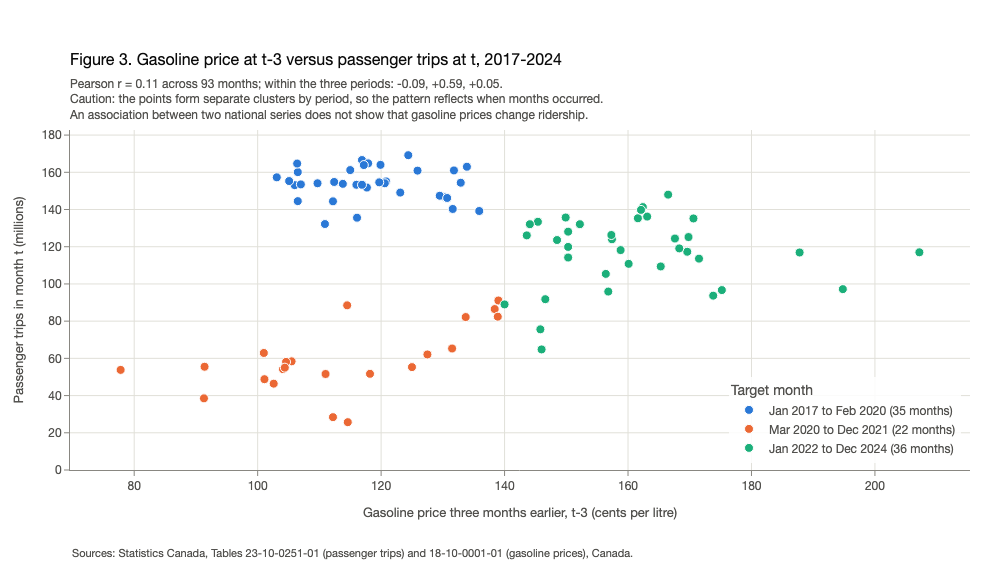

In [21]:
# Figure 3, with a short caution about interpretation
association_data = dev.dropna(subset=["gasoline_lag3"])
r_all = association.loc["All development months", ("Levels", "pearson_r")]
r_periods = ", ".join(f"{association.loc[name, ('Levels', 'pearson_r')]:+.2f}" for name, *_ in PERIODS)

fig = go.Figure()
add_association(fig, association_data)
fig.update_layout(
    height=580,
    margin=dict(t=130),
    title=dict(
        text="Figure 3. Gasoline price at t-3 versus passenger trips at t, 2017-2024",
        subtitle=dict(
            text=(f"Pearson r = {r_all:.2f} across {len(association_data)} months; within the three periods: "
                  f"{r_periods}.<br>Caution: the points form separate clusters by period, so the pattern "
                  "reflects when months occurred.<br>An association between two national series does not "
                  "show that gasoline prices change ridership."),
            font=dict(size=12, color=INK_SECONDARY)),
    ),
)
add_source(fig, SOURCE_BOTH)
fig.show()


### Figure 4. Prediction: actual, baseline, and model ridership for the 12 test months

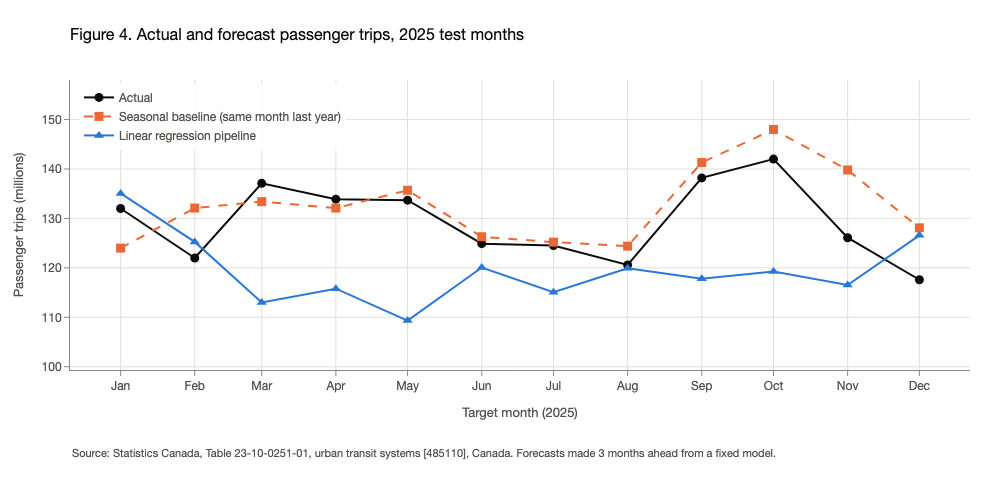

Test-period metrics, January to December 2025 (millions of trips):


,MAE (millions of trips),RMSE (millions of trips)
Seasonal baseline (same month last year),5.40,6.75
Linear regression pipeline,12.46,15.11


In [22]:
# Figure 4 and a small metric table
plot_months = pd.to_datetime(predictions["target_month"], format="%Y-%m")
series = [
    ("Actual", "actual_trips_millions", INK_PRIMARY, "solid", "circle", None),
    ("Seasonal baseline (same month last year)", "baseline_prediction", COLOR_BASELINE, "dash", "square",
     "baseline_error"),
    ("Linear regression pipeline", "model_prediction", COLOR_TRIPS, "solid", "triangle-up", "model_error"),
]

fig = go.Figure()
for label, column, color, dash, symbol, error_column in series:
    if error_column is None:
        customdata, hover = None, "Actual: %{y:.1f} million<extra></extra>"
    else:
        customdata = predictions[error_column]
        hover = f"{label}: %{{y:.1f}} million (error %{{customdata:+.1f}})<extra></extra>"
    fig.add_trace(go.Scatter(
        x=plot_months, y=predictions[column], mode="lines+markers", name=label,
        line=dict(color=color, dash=dash, width=2), marker=dict(symbol=symbol, size=9, color=color),
        customdata=customdata, hovertemplate=hover))

values = predictions[["actual_trips_millions", "baseline_prediction", "model_prediction"]]
fig.update_layout(
    title="Figure 4. Actual and forecast passenger trips, 2025 test months",
    xaxis_title="Target month (2025)", yaxis_title="Passenger trips (millions)", height=480,
    legend=dict(x=0.01, xanchor="left", y=0.99, yanchor="top"))
fig.update_xaxes(tickformat="%b", dtick="M1", hoverformat="%B %Y")
fig.update_yaxes(range=[values.min().min() - 10, values.max().max() + 10])
add_source(fig, SOURCE_TRANSIT + " Forecasts made 3 months ahead from a fixed model.")
fig.show()

print("Test-period metrics, January to December 2025 (millions of trips):")
display(metrics.round(2))


### Findings and limitations

**Observable problem.** Canadian urban transit ridership fell from 157.3 million trips in April 2019 to 25.7 million in April 2020 and has not fully returned. The 1,590.4 million trips in 2024 were 84.2% of the 2019 total, and the 1,552.6 million in 2025 were 82.2%. Within normal years, ridership follows a stable seasonal shape, lowest in July and August and highest in September and October.

**Predictive findings.** Forecasting three months ahead, the fixed linear regression pipeline had an MAE of 12.5 million trips (RMSE 15.1) over 2025. The same-month-last-year baseline had an MAE of 5.4 million (RMSE 6.8), so the model did not improve on the baseline. The model under-forecast 9 of the 12 months and missed the autumn rise. Gasoline prices showed only a weak, period-dependent association with ridership, and this evaluation gives no evidence that the gasoline feature improves forecasts.

**Planning use.** As a quick national benchmark three months ahead, last year's ridership for the same month was the more reliable reference in 2025. The pipeline gives a reproducible starting point for testing other predictors as more post-pandemic data accumulate.

**Limitations.** The sample is small: 84 training months, 22 of which fall between March 2020 and December 2021, when ridership collapsed and was rebuilding. That disruption likely distorted the fitted trend. Statistics Canada publishes these series with a delay and revises them. The scores use a snapshot downloaded in November 2026, not the data available at each forecast date, so they are not live forecasting performance. National totals also hide differences between cities and transit systems, and they cannot show crowding, service shortages, or how many buses are needed.


## 10. Reproducibility and maintenance

**Re-running this analysis.** Follow the README: create the environment from `requirements.txt`, then choose Restart Kernel and Run All. The notebook rebuilds `monthly_transportation.csv`, `model_data.csv`, `predictions_2025.csv`, and every figure from the files in `data/raw/`, with no credentials or manual code edits.

**Processing a later data release:**

1. **Acquire without overwriting.** Download the new full-table CSVs into a separate dated folder, so the November 2026 snapshot is preserved. Record the download date and checksums in the README, and point `TRANSIT_CSV` and `GASOLINE_CSV` at the new files.
2. **Validate automatically.** The same cells stop with an error if a dimension label changes, a unit or scale changes, or a month is duplicated. They report missing months, missing values, new status flags, and unmatched months before the join is accepted.
3. **Measure revisions.** Compare the new 2017-2025 values with the preserved snapshot, because Statistics Canada can revise published figures.
4. **Extend the evaluation.** Move `SCOPE_END` and `DEV_END` forward by one year to train through 2025 and test on 2026. The expected row counts are computed from the calendar, so the checks adapt. Fix the features and model before looking at the new test scores.
5. **Handle gaps correctly.** If a new release has missing predictor values, add a `SimpleImputer` inside the pipeline so it is fitted on training data only. The target is never imputed.
